# Model Evaluation — Teeth Segmentation
Evaluates the trained model on the validation set.
Reports mAP@50, mAP@75, MAE on tooth count, and saves visualisations.

## Imports

In [1]:
import random
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT_DIR = Path().resolve().parent
sys.path.append(str(ROOT_DIR))

DATA_DIR    = ROOT_DIR / 'data'
IMG_DIR     = DATA_DIR / 'processed'
ANN_DIR     = DATA_DIR / 'annotations'
RESULTS_DIR = ROOT_DIR / 'outputs' / 'results' / 'maskrcnn_torch'
csv_path = RESULTS_DIR / 'training_history.csv'


from configs.model_config import BINARY, CONF_THRESHOLD
from models.teeth_segmentation import (
    TeethDataset,
    build_model,
    evaluate,
    predict,
)
from utils.preprocessing import enhance_contrast, load_image

## Load Trained Model

In [2]:
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

NUM_CLASSES = 2 if BINARY else 36

model = build_model(NUM_CLASSES)

model.load_state_dict(
    torch.load(
        RESULTS_DIR / 'best.pth',
        map_location=DEVICE
    )
)

model.to(DEVICE)
model.eval()

print("Model loaded")


/tmp/ipykernel_974998/1126195551.py:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


Model loaded


## Run COCO Evaluation

In [3]:
evaluate()

  Loaded 67 images
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Evaluating 67 val images...
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.21s).
Accumulating evaluation results...
DONE (t=0.09s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.616
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.913
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.770
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.141
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.454
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.624
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.639
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.676
 Average Recall   

Coco defines small objects as area < 32x32 pixels. The metrics scores 0.8% on tiny teeth, meaning small object detection mostly fails (in this case, those teeth are usually partly visible wisdom tooth at image edges).
Coco defines medium area from 32x32 to 96x96 (in this case premolars) -> 42.4%
Area is considered large if above 96x96 pixels (large molars and canines) -> 62%, which proves that model performes best on large teeth.

## Plot Training/Validation Loss

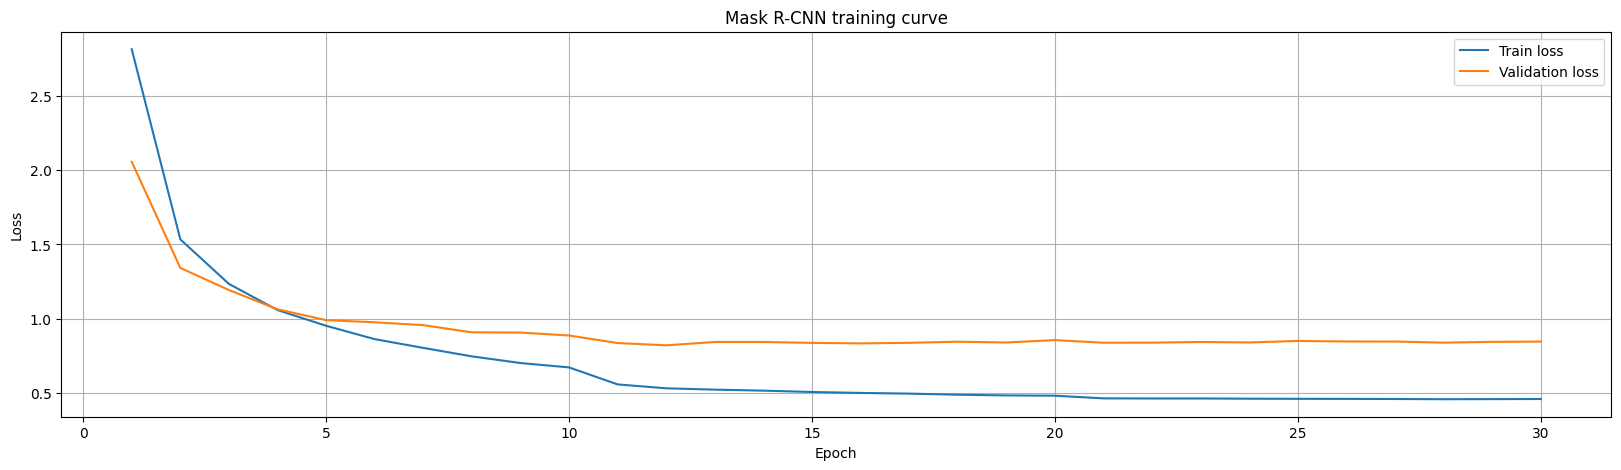

In [4]:
df = pd.read_csv(csv_path)

plt.figure(figsize=(20,5))
plt.plot(df['epoch'],df['train_loss'],label="Train loss")
plt.plot(df['epoch'],df['val_loss'],label= "Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Mask R-CNN training curve")
plt.legend()
plt.grid()
plt.show()

## Best epoch

In [5]:
best_epoch = int(df['val_loss'].idxmin()) + 1
best_val_loss = df['val_loss'].min()
print(f'Best epoch: {best_epoch}  val_loss: {best_val_loss:.4f}')

Best epoch: 12  val_loss: 0.8211


## Load Validation Dataset

In [6]:
dataset_val = TeethDataset(
    ANN_DIR / "val.json",
    IMG_DIR,
    binary=BINARY
)

print("Validation images:", len(dataset_val))

  Loaded 67 images
Validation images: 67


## Show Random Validation Images

In [7]:
val_image_infos = dataset_val.images

random_samples = random.sample(
    val_image_infos,
    5
)

for img_info in random_samples:
    print(img_info["file_name"])

for img_info in random_samples:

    image_path = IMG_DIR / img_info["file_name"]

    print(f"\nPredicting: {image_path.name}")

    predict(image_path)

234.jpg
55.jpg
64.jpg
70.jpg
190.jpg

Predicting: 234.jpg
Detected: 36 instances
Saved: /home/dorina/Downloads/dental-segmentation-v3/dental-segmentation/outputs/visualizations/torch_pred_234.jpg

Predicting: 55.jpg
Detected: 44 instances
Saved: /home/dorina/Downloads/dental-segmentation-v3/dental-segmentation/outputs/visualizations/torch_pred_55.jpg

Predicting: 64.jpg
Detected: 45 instances
Saved: /home/dorina/Downloads/dental-segmentation-v3/dental-segmentation/outputs/visualizations/torch_pred_64.jpg

Predicting: 70.jpg
Detected: 45 instances
Saved: /home/dorina/Downloads/dental-segmentation-v3/dental-segmentation/outputs/visualizations/torch_pred_70.jpg

Predicting: 190.jpg
Detected: 45 instances
Saved: /home/dorina/Downloads/dental-segmentation-v3/dental-segmentation/outputs/visualizations/torch_pred_190.jpg


## Display Saved Predictions

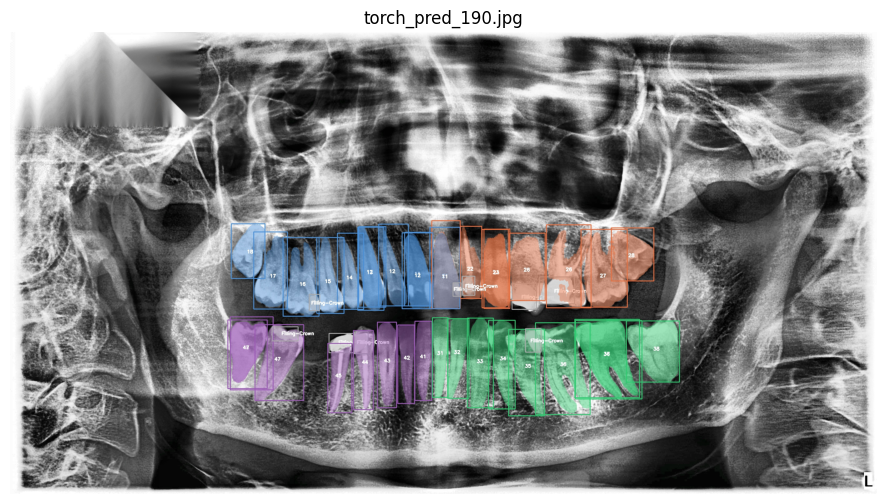

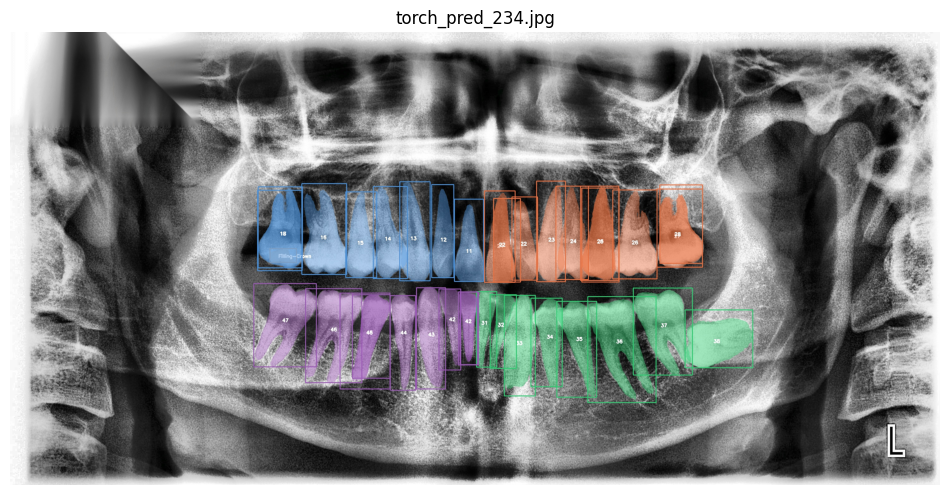

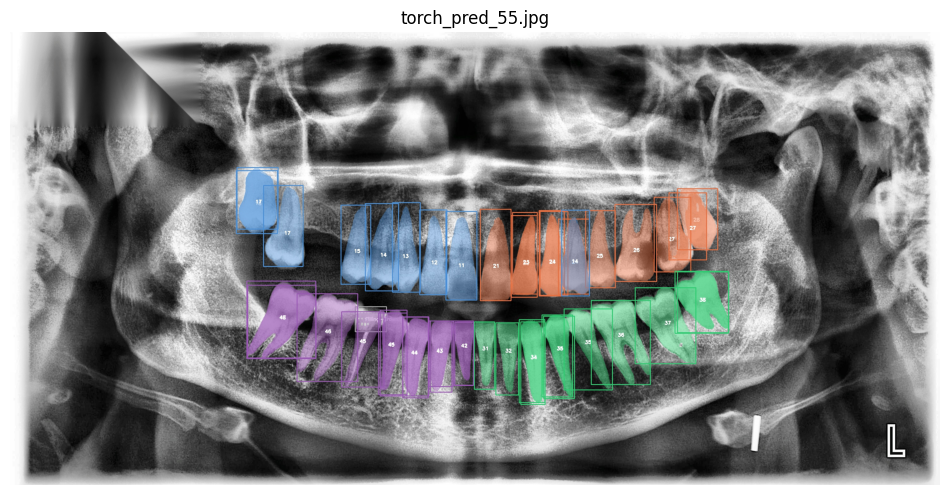

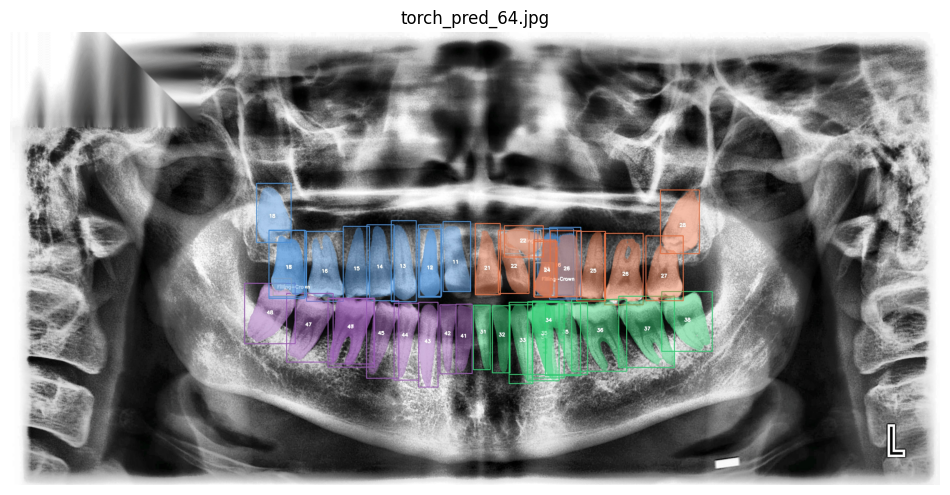

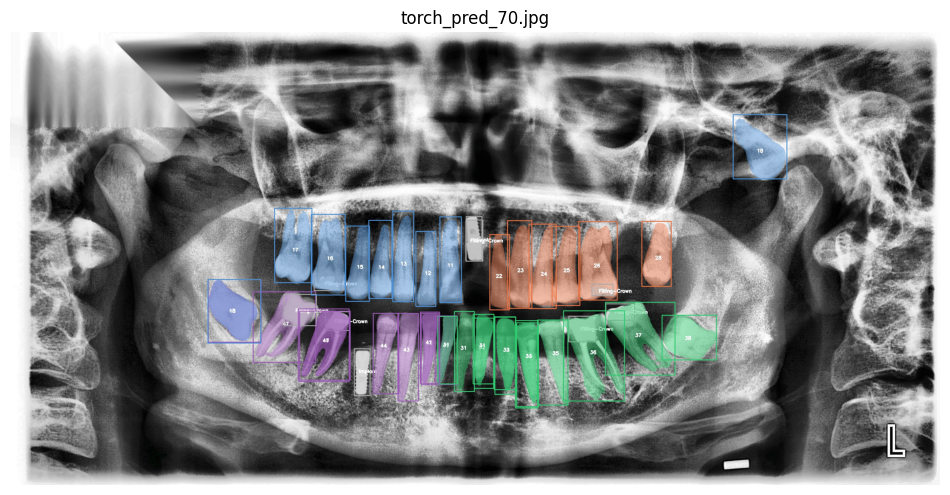

In [8]:

viz_dir = ROOT_DIR / "outputs" / "visualizations"

pred_files = sorted(
    viz_dir.glob("torch_pred_*")
)

for file in pred_files[-5:]:

    img = cv2.imread(str(file))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12,6))
    plt.imshow(img)
    plt.title(file.name)
    plt.axis("off")
    plt.show()

## Evaluate a specific image

In [9]:
image_path = DATA_DIR / "012.jpg"

predict(image_path)

Detected: 45 instances
Saved: /home/dorina/Downloads/dental-segmentation-v3/dental-segmentation/outputs/visualizations/torch_pred_012.jpg


array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [249, 249, 249],
        [244, 244, 244],
        ...,
        [238, 238, 238],
        [245, 245, 245],
        [252, 252, 252]],

       [[249, 249, 249],
        [253, 253, 253],
        [247, 247, 247],
        ...,
        [244, 244, 244],
        [250, 250, 250],
        [252, 252, 252]],

       [[248, 248, 248],
        [253, 253, 253],
        [248, 248, 248],
        ...,
        [252, 252, 252],
        [255, 255, 255],
        [255, 255, 255]]

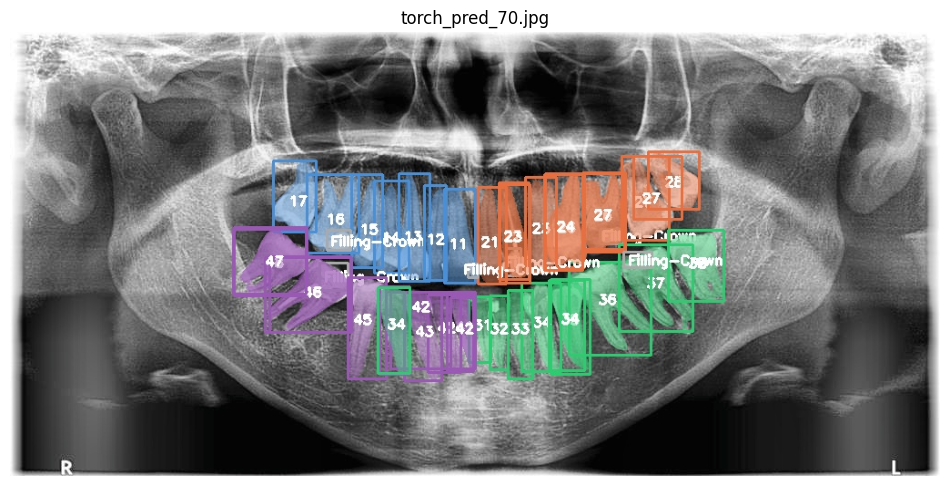

In [10]:
img = cv2.imread(str(ROOT_DIR / "outputs" / "visualizations"/"torch_pred_012.jpg"))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12,6))
plt.imshow(img)
plt.title(file.name)
plt.axis("off")
plt.show()

In [11]:
import json

import torchvision.transforms.functional as F

anns_by_image = {}
with open(ANN_DIR / 'val.json') as f:
    for ann in json.load(f)['annotations']:
        anns_by_image.setdefault(ann['image_id'], []).append(ann)

n_det, n_gt = [], []
with torch.no_grad():
    for img in dataset_val.images:
        t = F.to_tensor(enhance_contrast(load_image(str(IMG_DIR/img['file_name'])), 'clahe')).unsqueeze(0).to(DEVICE)
        scores = model(t)[0]['scores'].cpu().numpy()
        n_det.append((scores >= CONF_THRESHOLD).sum())
        n_gt.append(len(anns_by_image.get(img['id'], [])))

diffs = np.abs(np.array(n_det) - np.array(n_gt))
print(f'MAE: {diffs.mean():.1f} teeth | detected: {np.mean(n_det):.1f} vs GT: {np.mean(n_gt):.1f}')

MAE: 10.5 teeth | detected: 40.9 vs GT: 30.4
